# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import meshio
from time import time
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

# make data

In [68]:
class sampler:

    def __init__(self, lb, ub, nb_cell):

        self.lb = lb
        self.ub = ub

        self.nb_cell = nb_cell

        self.centers = self.make_centers()
        self.nb_centers=len(self.centers)
        
        self._bank = tf.constant(np.load("../data/bank.npy"),dtype=np.float32)
        scale = tf.stack([self.db,self.da])
        shift = tf.stack([-0.5*self.db, -0.5 * self.da])
        self._bank *= scale
        self._bank += shift
        
        self.mask = tf.ones([3, 3, 1, 1])
        
    def make_centers(self):

        self.lb_border = tf.linspace(self.lb[1],self.ub[1], self.nb_cell[0]+1)
        a = self.lb_border[:-1]
        self.da = a[1] - a[0]
        a = a + self.da/2

        self.ub_border = tf.linspace(self.lb[2],self.ub[2], self.nb_cell[1]+1)
        b = self.ub_border[:-1] 
        self.db = b[1]-b[0]
        b = b + self.db/2
        
        aa,bb = tf.meshgrid(a,b)
        aa = tf.reshape(aa,[-1])
        bb = tf.reshape(bb,[-1])
        aabb = tf.stack([bb,aa],axis=1)

        return aabb
    
    def sample(self, func, nb_sample):

        self.t_r = tf.random.uniform((self.nb_centers,1), self.lb[0], self.ub[0], dtype='float32')
        X = tf.concat([self.t_r, self.centers], axis=1)
        values_at_center = func(X)
        
        current=tf.constant(np.random.randint(0,10_000),dtype=tf.int32)
        return self.sample_acc(values_at_center, current, nb_sample)
    
    @tf.function
    def sample_acc(self, values_at_center, current, nb_sample):
        print("traçage de la fonction sample")
        
        # smoothing
        values_matrix = tf.reshape(values_at_center,[1,self.nb_cell[0],self.nb_cell[1],1])
        C = tf.nn.conv2d(values_matrix, self.mask, [1, 1, 1, 1], padding="SAME")
        values_at_center = tf.reshape(C[0,:,:,0],[-1])
        
        # normalize density
        values_at_center-=tf.reduce_min(values_at_center)
        values_at_center/=tf.reduce_sum(values_at_center)
        
        samples=[]
        
        for i in range(len(values_at_center)):
            center = self.centers[i]
            value = values_at_center[i]
            n = tf.floor(value*nb_sample) + 10
            n = tf.cast(n,tf.int32)

            sample = self._bank[current:(current + n)]
            current = current+n
            sample += center
            samples.append(sample)

        return tf.concat(samples,axis=0)

In [69]:
%%time 
samp = sampler(lb, ub, [10,10])
centres = samp.make_centers()
res = samp.sample(grad_J, 5_000)

traçage de la fonction sample
CPU times: user 2.35 s, sys: 15.2 ms, total: 2.37 s
Wall time: 2.37 s


In [70]:
len(res)

5982

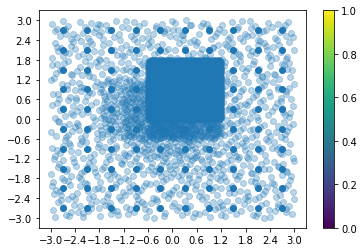

In [71]:
plt.xticks(samp.lb_border)
plt.yticks(samp.ub_border)
plt.plot(res[:,1],res[:,0],'o',alpha=0.3)
plt.scatter(centres[:, 1], centres[:, 0], cmap="jet", alpha=1.)
plt.colorbar()

In [66]:
samp.t_r

<tf.Tensor: shape=(100, 1), dtype=float32, numpy=
array([[4.25342   ],
       [1.5515321 ],
       [0.5742711 ],
       [1.4348012 ],
       [2.7424967 ],
       [2.1949875 ],
       [0.39644003],
       [0.6142324 ],
       [4.340762  ],
       [2.203455  ],
       [0.9261668 ],
       [1.1967981 ],
       [0.8160931 ],
       [4.250409  ],
       [1.7326492 ],
       [4.423501  ],
       [4.279298  ],
       [2.5430417 ],
       [2.4619246 ],
       [0.41555822],
       [2.3381436 ],
       [2.158481  ],
       [2.6538844 ],
       [0.76503754],
       [1.5419173 ],
       [1.9258022 ],
       [4.452042  ],
       [2.0984733 ],
       [0.17133892],
       [1.3303566 ],
       [3.9067082 ],
       [0.9666258 ],
       [1.1071002 ],
       [4.3840237 ],
       [1.6654915 ],
       [0.22749066],
       [3.0573268 ],
       [4.275461  ],
       [2.9497087 ],
       [2.591731  ],
       [2.3194165 ],
       [2.9156928 ],
       [4.604111  ],
       [4.2005467 ],
       [1.8951142 ],
     

In [5]:
model = PhysicsInformedNN(lb, ub, output_dim=4, num_hidden_layers=8, num_neurons_per_layer=256, activation='tanh')
model.build(input_shape=(None,3))
model.load_weights(WEIGHT_PATH+'best_weight_MHD-megacool.h5')

In [57]:
def grad_J(X):
    
    t, x, y = X[:,0:1], X[:,1:2], X[:,2:3]
    with tf.GradientTape(persistent=True) as tape:
        tape.watch(x)
        tape.watch(y)

        u = model(tf.stack([t[:,0], x[:,0], y[:,0]], axis=1))
        omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]

        J_x = tape.gradient(J, x)
        J_y = tape.gradient(J, y)
    del tape
    
    grad = J_x**2+J_y**2
    return grad[:,0]

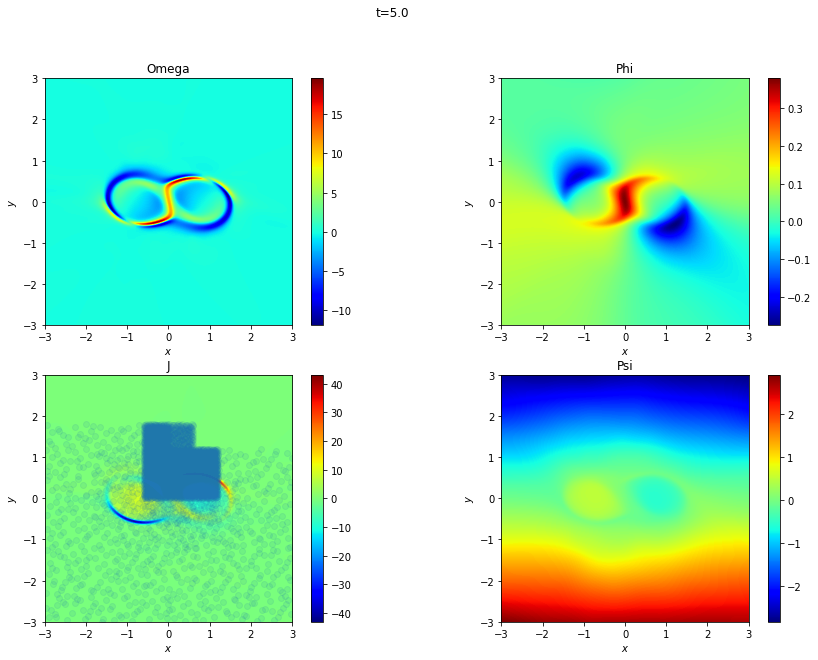

In [67]:
N = 500
t = 5.

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
u = model(tf.cast(Xgrid,DTYPE))

omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(omega, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')
axs[2].plot(res[:,1],res[:,0],'o',alpha=0.1)

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('t={}'.format(t))
plt.show()